# Boosting and Stacking Exercises
Exerciții de stimulare și stivuire

![Boosting.png](Assets/Boosting.png)

# Obiectivele învățării

- Explicarea modului în care algoritmul boosting ajută la reducerea varianței și a prejudecăților.


## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones] (https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construită pe baza înregistrărilor participanților la studiu care efectuează activități de viață zilnică (ADL) în timp ce poartă un smartphone cu senzori inerțiali încorporați. Obiectivul este de a clasifica activitățile într-una dintre cele șase activități (mersul pe jos, mersul pe scări, mersul pe scări, șezutul, statul în picioare și întinderea) efectuate.

Pentru fiecare înregistrare din setul de date se furnizează: 

- accelerația triaxială de la accelerometru (accelerația totală) și accelerația corpului estimată. 
- Viteza unghiulară triaxială de la giroscop. 
- Un vector de 561 de caracteristici cu variabile în domeniul timpului și al frecvenței. 
- Eticheta activității sale. 

Mai multe informații despre caracteristici sunt disponibile pe site-ul de mai sus.

In [1]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier


In [2]:
import warnings
warnings.filterwarnings('ignore')   # ascundem warning-urile de la sklearn

## Întrebare 1

* Importați datele din fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv` și examinați forma și tipurile de date. Pentru tipurile de date, vor fi prea multe pentru a lista fiecare coloană separat. Mai degrabă, agregați tipurile după număr.
* Determinați dacă coloanele float trebuie să fie scalate.

In [3]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

In [4]:
data.shape

(10299, 562)

Datele au destul de multe coloane predictoare.

In [5]:
# cate coloane avem de fiecare tip
data.dtypes.value_counts()

float64    561
str          1
Name: count, dtype: int64

Și toate sunt valori float. Singura valoare care nu este float este coloana categoriilor, care este cea care este prezisă.

In [6]:
# min si max pentru toate coloanele float
print(data.iloc[:, :-1].min().value_counts())
print(data.iloc[:, :-1].max().value_counts())

-1.0    561
Name: count, dtype: int64
1.0    561
Name: count, dtype: int64


Valoarea minimă și maximă pentru coloanele float este -1.0 și, respectiv, 1.0. Cu toate acestea, scalarea nu este niciodată necesară pentru metodele bazate pe arbori.

## Întrebare 2

* Codificați activitățile în numere întregi.
* Împărțiți datele în seturi de date de instruire și de testare. Decideți dacă datele vor fi stratificate sau nu în timpul împărțirii tren/test.

In [7]:
# activitatile (text) -> numere 0-5
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])

pd.DataFrame({'activitate': le.classes_,
              'nr_randuri': data['Activity'].value_counts().sort_index()})

,activitate,nr_randuri
Activity,,
0,LAYING,1944
1,SITTING,1777
2,STANDING,1906
3,WALKING,1722
4,WALKING_DOWNSTAIRS,1406
5,WALKING_UPSTAIRS,1544


**NOTA**: Urmează să creăm seturi de instruire și de testare din `data`. Pe aceste seturi de date, vom rula căutări de tip grilă pe mai multe opțiuni de parametri. Acest lucru poate dura ceva timp. Pentru a scurta timpul de căutare în grilă, nu ezitați să reduceți eșantionarea `date` și să creați `X_train, X_test, y_train, y_test` din setul de date redus la eșantionare.

Împărțiți acum datele în seturi de date de instruire și de testare. O împărțire stratificată nu a fost utilizată aici. Dacă există probleme cu oricare dintre parametrii de eroare pe setul de testare, poate fi o idee bună să începeți ajustarea modelului folosind o împărțire stratificată. Totuși, Boosting este un model destul de puternic, așa că s-ar putea să nu fie necesar în acest caz.

In [8]:
# 70% train / 30% test, fara stratificare (clasele sunt destul de echilibrate)
feature_cols = [c for c in data.columns if c != 'Activity']

X_train, X_test, y_train, y_test = train_test_split(data[feature_cols], data['Activity'],
                                                    test_size=0.3, random_state=42)
X_train.shape, X_test.shape

((7209, 561), (3090, 561))

## Întrebare 3

* Potriviți modele de arbori gradient boosted cu toți parametrii setați la valorile implicite pentru următoarele numere de arbori (`n_estimatori = [25, 50, 100, 200, 400]`) și evaluați precizia pe datele de test pentru fiecare dintre aceste modele. 
* Reprezentați grafic acuratețea în funcție de numărul de estimatori.

**Nota:** Executarea acestei întrebări poate dura ceva timp, în funcție de cât de multe valori diferite sunt potrivite pentru estimatori. Setarea `max_features=4` în clasificatorul gradient boosting va crește rata de convergență.

De asemenea, acest lucru este similar cu întrebarea 3 din săptămâna 9, cu excepția faptului că nu există o eroare în afara sacului pentru modelele boosted. Iar setarea `warm_flag=True` are o eroare în modelul gradient boosted, deci nu o folosiți. Creați pur și simplu modelul în interiorul buclei `for` și setați numărul de estimatori în acest moment. Acest lucru va face ca ajustarea să dureze puțin mai mult. În plus, ajustarea modelelor boosting tinde să dureze mai mult decât cea a modelelor bagged, deoarece cioturile de decizie trebuie ajustate succesiv.

In [9]:
# gradient boosting cu numar diferit de arbori, restul parametrilor default
# (max_features=4 doar ca sa mearga mai repede)
n_list = [25, 50, 100, 200, 400]
acc_list = []

for n in n_list:
    GBC = GradientBoostingClassifier(n_estimators=n, max_features=4, random_state=42)
    GBC.fit(X_train, y_train)
    acc = accuracy_score(y_test, GBC.predict(X_test))
    acc_list.append(acc)
    print(n, 'arbori -> accuracy =', round(acc, 4))

25 arbori -> accuracy = 0.9311


50 arbori -> accuracy = 0.9595


100 arbori -> accuracy = 0.9764


200 arbori -> accuracy = 0.9841


400 arbori -> accuracy = 0.9867


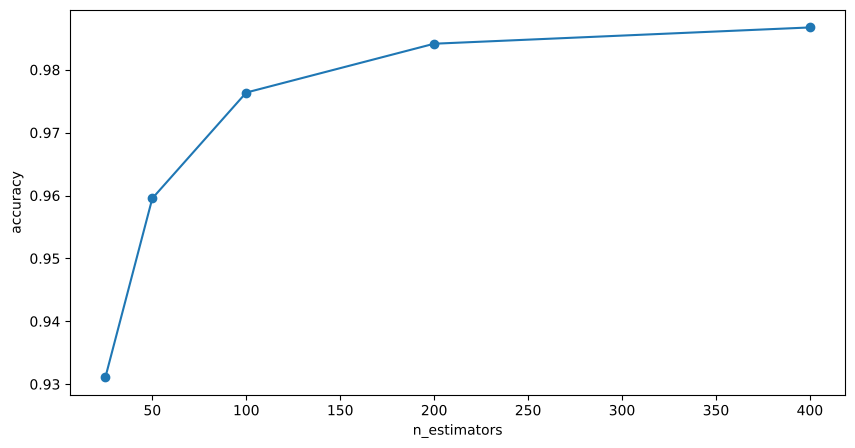

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

acc_df = pd.DataFrame({'accuracy': acc_list}, index=n_list)

ax = acc_df.plot(marker='o', figsize=(10, 5), legend=False)
ax.set(xlabel='n_estimators', ylabel='accuracy');

## Întrebarea 4

* Utilizând o căutare în grilă cu validare încrucișată, potriviți un nou clasificator gradient boosted cu o listă de estimatori, similar cu întrebarea 3. De asemenea, luați în considerare varierea ratelor de învățare (0,1, 0,01, 0,001 etc.), a valorii subeșantionării (1,0 sau 0,5) și a numărului maxim de caracteristici (1, 2 etc.).
* Examinați parametrii modelului cel mai bine adaptat.
* Calculați parametrii de eroare relevanți pentru acest model și examinați matricea de confuzie.

**Notă:** această întrebare poate dura ceva timp pentru a fi executată, în funcție de câte caracteristici sunt asociate cu căutarea în grilă. Se recomandă să începeți cu doar câteva pentru a vă asigura că totul funcționează corect și apoi să adăugați mai multe caracteristici. Setarea `max_features=4` în clasificatorul gradient boosting va crește rata de convergență.

In [11]:
# grid search cu validare incrucisata (cv=3 ca sa mearga mai repede)
param_grid = {'n_estimators': [100, 200, 400],
              'learning_rate': [0.1, 0.01],
              'subsample': [1.0, 0.5],
              'max_features': [2, 4]}

GV_GBC = GridSearchCV(GradientBoostingClassifier(random_state=42),
                      param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1)
GV_GBC.fit(X_train, y_train)

# parametrii celui mai bun model
print(GV_GBC.best_params_)
print('accuracy CV:', round(GV_GBC.best_score_, 4))

{'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 400, 'subsample': 1.0}
accuracy CV: 0.986


**Metrica erorilor.** Raportul de clasificare este deosebit de convenabil pentru cazurile cu mai multe clase.

In [12]:
y_pred = GV_GBC.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.97      0.97      0.97       563
           2       0.97      0.97      0.97       547
           3       1.00      1.00      1.00       539
           4       1.00      1.00      1.00       420
           5       0.99      1.00      0.99       424

    accuracy                           0.99      3090
   macro avg       0.99      0.99      0.99      3090
weighted avg       0.99      0.99      0.99      3090



**Matricea de confuzie.** Rețineți că modelul gradient boosted are o mică problemă în a distinge între clasele de activitate 1 și 2.

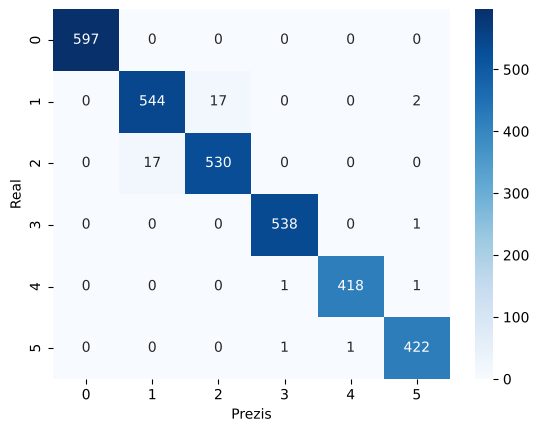

In [13]:
cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='Prezis', ylabel='Real');

## Întrebarea 5

* Creați un model AdaBoost și potriviți-l folosind grid search, la fel ca la întrebarea 4. Încercați o gamă de estimatori între 100 și 200.
* Comparați erorile de la AdaBoost cu cele de la GradientBoostedClassifier.

**NOTĂ:** Setarea `max_features=4` în clasificatorul arbore de decizie utilizat ca clasificator de bază pentru AdaBoost va crește rata de convergență.

In [14]:
# AdaBoost cu arbore de decizie ca model de baza
ABC = AdaBoostClassifier(DecisionTreeClassifier(max_features=4), random_state=42)

# incercam si adancimea arborelui (max_depth=1 e ciotul de decizie)
param_grid = {'n_estimators': [100, 150, 200],
              'learning_rate': [1.0, 0.1],
              'estimator__max_depth': [1, 2, 3]}

GV_ABC = GridSearchCV(ABC, param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1)
GV_ABC.fit(X_train, y_train);

Cel mai potrivit model.

In [15]:
print(GV_ABC.best_params_)
print('accuracy CV:', round(GV_ABC.best_score_, 4))

{'estimator__max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 200}
accuracy CV: 0.9546


**Parametrii de eroare.** Observați că problemele cu clasele 1 și 2 par să fi devenit mai problematice și includ acum clasa 0. De asemenea, observați alte probleme pentru clasele 3 - 5. AdaBoost este foarte sensibil la valorile aberante, deci aceasta ar putea fi problema aici.

              precision    recall  f1-score   support

           0       1.00      0.99      1.00       597
           1       0.93      0.90      0.92       563
           2       0.90      0.93      0.92       547
           3       0.99      0.98      0.99       539
           4       0.99      0.98      0.98       420
           5       0.96      0.98      0.97       424

    accuracy                           0.96      3090
   macro avg       0.96      0.96      0.96      3090
weighted avg       0.96      0.96      0.96      3090



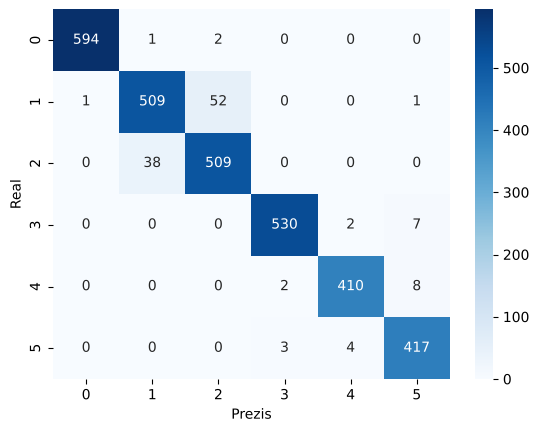

In [16]:
y_pred = GV_ABC.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='Prezis', ylabel='Real');

In [17]:
# comparatie pe test
print('GradientBoosting:', round(accuracy_score(y_test, GV_GBC.predict(X_test)), 4))
print('AdaBoost:        ', round(accuracy_score(y_test, GV_ABC.predict(X_test)), 4))

GradientBoosting: 0.9867


AdaBoost:         0.9608


**Comparatie:** AdaBoost iese mai slab decat GradientBoosting (accuracy mai mica) si face mai multe greseli, mai ales intre clasele 1 si 2 (SITTING / STANDING).

## Întrebare 6

* Adaptați un model de regresie logistică cu regularizare. Acesta poate fi o replică a unui model care a funcționat bine în exercițiile din săptămâna 4.
* Folosind `VotingClassifier`, ajustați modelul de regresie logistică împreună cu modelul GratientBoostedClassifier sau AdaBoost (sau ambele) de la întrebările 4 și 5.
* Determinați eroarea ca mai înainte și comparați rezultatele cu modelul (modelele) corespunzător(e) cu amplificare prin gradient.
* Reprezentați matricea de confuzie pentru cel mai bun model creat în acest set de exerciții.

In [18]:
# regresie logistica cu regularizare L2 (default), C ales prin cross-validation
LR = LogisticRegressionCV(Cs=5, cv=4, max_iter=1000, n_jobs=-1)
LR.fit(X_train, y_train)

print('C ales:', LR.C_[0])

C ales: 100.0


Verificați erorile și matricea de confuzie pentru modelul de regresie logistică.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.95      0.95      0.95       563
           2       0.96      0.95      0.95       547
           3       0.99      1.00      1.00       539
           4       1.00      0.99      1.00       420
           5       0.98      1.00      0.99       424

    accuracy                           0.98      3090
   macro avg       0.98      0.98      0.98      3090
weighted avg       0.98      0.98      0.98      3090



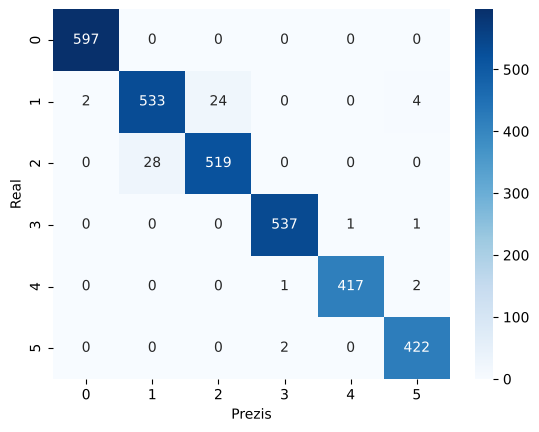

In [19]:
y_pred = LR.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='Prezis', ylabel='Real');

Și acum modelul stivuit.

In [20]:
# VotingClassifier: regresie logistica + cel mai bun gradient boosting
VC = VotingClassifier([('LR', LR), ('GBC', GV_GBC.best_estimator_)], voting='soft')
VC.fit(X_train, y_train)

y_pred = VC.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.97      0.96      0.96       563
           2       0.97      0.97      0.97       547
           3       1.00      1.00      1.00       539
           4       1.00      1.00      1.00       420
           5       0.99      1.00      0.99       424

    accuracy                           0.99      3090
   macro avg       0.99      0.99      0.99      3090
weighted avg       0.99      0.99      0.99      3090



In [21]:
# comparam toate modelele pe test
models = {'GradientBoosting': GV_GBC,
          'AdaBoost': GV_ABC,
          'LogisticRegression': LR,
          'Voting (LR + GBC)': VC}

scores = pd.Series({name: accuracy_score(y_test, m.predict(X_test)) for name, m in models.items()})
scores.sort_values(ascending=False)

GradientBoosting      0.986731
Voting (LR + GBC)     0.985761
LogisticRegression    0.978964
AdaBoost              0.960841
dtype: float64

**Concluzie:** Cel mai bun model e GradientBoosting din grid search. Modelul combinat (Voting LR + GBC) iese aproape la fel, deci aici combinarea cu regresia logistica nu a adus o imbunatatire. Greselile care raman sunt mai ales intre clasele 1 si 2 (SITTING / STANDING).

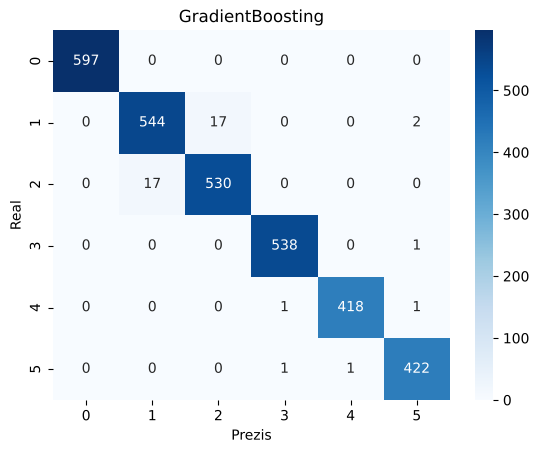

In [22]:
# matricea de confuzie pentru cel mai bun model
best = scores.idxmax()
y_pred = models[best].predict(X_test)

cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='Prezis', ylabel='Real', title=best);